# 03 — Regressão: previsão do PIB municipal

**Trabalho 2 – Previsão do PIB dos Municípios da Região Sul (PR, SC, RS)**

Objetivo: prever o valor do PIB de cada município. Este notebook cobre a **Etapa A** do enunciado: escolher e avaliar os modelos usando dados até 2022 e testar contra o PIB oficial de 2023.
A previsão de 2024 (Etapa B) fica no notebook 05, com o modelo escolhido aqui.

**Métricas exigidas:** R² e MAPE do PIB. Também reportamos a mediana do erro percentual (MdAPE) e o R² do crescimento, que mostra quanto o modelo acrescenta além de copiar o PIB do ano anterior.

## Estratégia

| Item | Escolha | Justificativa |
|---|---|---|
| Alvo de treino | `cresc_pib_log` = log(PIB_t / PIB_t-1) | o nível é dominado pelo tamanho do município; o erro no crescimento em log ≈ erro percentual no PIB, que é o MAPE |
| PIB previsto | PIB_t-1 × exp(crescimento previsto) | o PIB de t-1 é conhecido no momento da previsão |
| Validação | janela expansiva: treina [início, v-1], valida v, com v = 2019, 2020, 2021, 2022 | respeita o tempo; cobre um ano "normal" (2019), a pandemia (2020), o boom de commodities (2021) e a estiagem (2022) |
| Critério de escolha | MAPE médio nos 4 anos de validação | é a métrica pedida e pesa todos os municípios igualmente |
| Teste final | treina com alvos até 2022 e prevê 2023 | **2023 não é usado em nenhuma escolha**, só na avaliação final |

**Modelos (≥ 2 exigidos):**
- 3 baselines sem aprendizado: persistência, média de 3 anos do município e crescimento da UF em t-1;
- 2 lineares: **Ridge** e **Huber**, uma regressão robusta que reduz o peso dos saltos extremos;
- 2 de árvores: **Random Forest** e **LightGBM** (gradient boosting);
- 1 **ensemble**: a média das previsões de Ridge, Random Forest e LightGBM.

In [1]:
import sys, json, time, warnings
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import features as ft
from src import modelos as m
from src import viz

viz.aplica_estilo()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)

DIR_RES = RAIZ / "reports" / "resultados"
DIR_RES.mkdir(parents=True, exist_ok=True)
DIR_PRED = RAIZ / "data" / "predictions"

dataset = ft.carrega_dataset()
numericas, categoricas = ft.colunas_modelo(dataset)
INICIO_PADRAO = ft.PRIMEIRO_ANO_AMOSTRA_PADRAO
print(f"Dataset: {dataset.shape} | {len(numericas)} numéricas + {len(categoricas)} categóricas")
print("Linhas por conjunto:", dataset["conjunto"].value_counts().to_dict())

Dataset: (20247, 58) | 39 numéricas + 3 categóricas
Linhas por conjunto: {'treino': 17865, 'teste_2023': 1191, 'previsao_2024': 1191}


## 1. Baselines

Qualquer modelo útil precisa superar estas regras simples.

In [2]:
res_baselines = {nome: m.valida_temporal(nome, {}, dataset, INICIO_PADRAO) for nome in m.BASELINES}
pd.concat({n: r.por_ano[["MAPE_%", "MdAPE_%", "R2_pib", "R2_crescimento"]] for n, r in res_baselines.items()}, axis=1).T

ano_validacao                                   2019   2020   2021   2022
Persistência (PIB_t = PIB_t-1) MAPE_%          7.115 11.915 19.221 15.043
                               MdAPE_%         5.993  9.982 16.918 10.527
                               R2_pib          0.992  0.989  0.975  0.985
                               R2_crescimento -0.238 -0.382 -1.355 -0.004
Média 3 anos do município      MAPE_%          8.222 11.439 16.027 21.121
                               MdAPE_%         6.033  8.864 12.367 11.489
                               R2_pib          0.995  0.979  0.985  0.988
                               R2_crescimento -0.629 -0.277 -0.940 -0.815
Crescimento da UF em t-1       MAPE_%          6.394 10.135 17.602 25.372
                               MdAPE_%         4.813  7.134 14.070 16.376
                               R2_pib          0.997  0.979  0.982  0.986
                               R2_crescimento  0.016 -0.021 -1.325 -1.181

O **R² no nível do PIB fica acima de 0,97 até para a persistência**, que só copia o PIB do ano anterior. Isso confirma que o R² do nível, sozinho, não mede a qualidade do modelo: ele reflete a diferença de tamanho entre municípios.
O **R² do crescimento** negativo mostra que nenhum baseline acerta *quem* cresce mais que a média.

## 2. Busca de hiperparâmetros (validação temporal, alvos a partir de 2013)

In [3]:
t0 = time.time()
buscas = {}
for nome in m.FABRICAS_REGRESSAO:
    print(f"== {nome}: {len(m.combinacoes(m.GRADES_REGRESSAO[nome]))} combinações × {len(m.ANOS_VALIDACAO)} anos")
    buscas[nome] = m.busca_hiperparametros(nome, dataset, INICIO_PADRAO, verbose=False)
    melhor = buscas[nome].iloc[0]
    print(f"   melhor: {melhor['params']}  ->  MAPE médio {melhor['MAPE_%']:.2f}%")
print(f"Tempo total: {(time.time() - t0) / 60:.1f} min")

tabela_busca = pd.concat(buscas.values(), ignore_index=True)
tabela_busca.assign(params=tabela_busca["params"].astype(str)).to_csv(DIR_RES / "regressao_busca_hiperparametros.csv", index=False)

== Ridge: 5 combinações × 4 anos


   melhor: {'alpha': 1000}  ->  MAPE médio 9.73%
== Huber: 9 combinações × 4 anos


   melhor: {'alpha': 1, 'epsilon': 2.0}  ->  MAPE médio 10.57%
== Random Forest: 6 combinações × 4 anos


   melhor: {'min_samples_leaf': 5, 'max_features': 0.6}  ->  MAPE médio 7.80%
== LightGBM: 24 combinações × 4 anos


   melhor: {'objective': 'l2', 'num_leaves': 15, 'min_child_samples': 20, 'colsample_bytree': 0.6, 'subsample': 0.8, 'reg_lambda': 0.0}  ->  MAPE médio 7.49%
Tempo total: 2.8 min


In [4]:
# As 5 melhores combinações de cada modelo
for nome, tab in buscas.items():
    print(f"\n{nome}")
    display(tab.head(5)[["params", "MAPE_%", "MdAPE_%", "MAPE_pior_ano_%", "R2_crescimento", "R2_pib"]])


Ridge


,params,MAPE_%,MdAPE_%,MAPE_pior_ano_%,R2_crescimento,R2_pib
0,{'alpha': 1000},9.729,7.560,17.036,0.308,0.985
1,{'alpha': 1},9.773,7.507,17.651,0.280,0.986
2,{'alpha': 10},9.792,7.531,17.775,0.278,0.986
3,{'alpha': 100},9.796,7.548,17.766,0.282,0.986
4,{'alpha': 0.1},10.185,7.686,16.727,0.249,0.984



Huber


,params,MAPE_%,MdAPE_%,MAPE_pior_ano_%,R2_crescimento,R2_pib
0,"{'alpha': 1, 'epsilon': 2.0}",10.566,8.162,17.198,0.219,0.983
1,"{'alpha': 1, 'epsilon': 1.1}",10.569,8.147,17.481,0.210,0.984
2,"{'alpha': 1, 'epsilon': 1.35}",10.581,8.172,17.266,0.213,0.983
3,"{'alpha': 0.0001, 'epsilon': 1.35}",11.194,8.508,16.302,0.137,0.980
4,"{'alpha': 0.01, 'epsilon': 2.0}",11.245,8.486,16.592,0.133,0.980



Random Forest


,params,MAPE_%,MdAPE_%,MAPE_pior_ano_%,R2_crescimento,R2_pib
0,"{'min_samples_leaf': 5, 'max_features': 0.6}",7.798,5.589,10.439,0.454,0.989
1,"{'min_samples_leaf': 5, 'max_features': 0.33}",7.839,5.575,10.272,0.446,0.990
2,"{'min_samples_leaf': 20, 'max_features': 0.6}",8.079,5.699,10.816,0.422,0.990
3,"{'min_samples_leaf': 20, 'max_features': 0.33}",8.170,5.669,10.719,0.410,0.989
4,"{'min_samples_leaf': 50, 'max_features': 0.6}",8.445,5.987,11.188,0.386,0.989



LightGBM


,params,MAPE_%,MdAPE_%,MAPE_pior_ano_%,R2_crescimento,R2_pib
0,"{'objective': 'l2', 'num_leaves': 15, 'min_chi...",7.489,5.389,10.461,0.473,0.990
1,"{'objective': 'l2', 'num_leaves': 15, 'min_chi...",7.503,5.345,10.413,0.469,0.990
2,"{'objective': 'huber', 'num_leaves': 31, 'min_...",7.508,5.351,10.124,0.469,0.989
3,"{'objective': 'l2', 'num_leaves': 31, 'min_chi...",7.509,5.324,10.280,0.466,0.990
4,"{'objective': 'l1', 'num_leaves': 15, 'min_chi...",7.524,5.260,10.225,0.471,0.991


## 3. Janela de treino: a partir de que ano treinar?

A janela é tratada como **mais um hiperparâmetro**: com os melhores hiperparâmetros de cada modelo, repetimos a validação com três inícios (2010, 2013 e 2016) e escolhemos o **par (modelo, janela) com menor MAPE médio**.
Janelas mais longas têm mais dados. Janelas mais curtas se parecem mais com o presente: inflação menor, sem o ciclo de crescimento alto dos anos 2010–2013.

Nesta etapa também entra um **ensemble**: a média simples das previsões de Ridge, Random Forest e LightGBM, com os hiperparâmetros já escolhidos.
Modelos de natureza diferente, um linear e dois de árvores, erram em anos diferentes, e a média tende a ser mais estável.

In [5]:
melhores = {nome: tab.iloc[0]["params"] for nome, tab in buscas.items()}
params_modelos = {**melhores, m.NOME_ENSEMBLE: {c: melhores[c] for c in m.COMPONENTES_ENSEMBLE}}
janelas = {}
for inicio in [2010, 2013, 2016]:
    for nome, p in params_modelos.items():
        janelas[(nome, inicio)] = m.valida_temporal(nome, p, dataset, inicio).media["MAPE_%"]
tab_janelas = pd.Series(janelas).unstack()
melhor_modelo, inicio_escolhido = tab_janelas.stack().idxmin()
inicio_escolhido = int(inicio_escolhido)
tab_janelas.columns = [f"início {c}" for c in tab_janelas.columns]
print(f"Melhor par na validação: {melhor_modelo} com alvos a partir de {inicio_escolhido} "
      f"(MAPE médio {tab_janelas.min().min():.2f}%)")
tab_janelas.round(2)

Melhor par na validação: Ensemble (Ridge + RF + LightGBM) com alvos a partir de 2016 (MAPE médio 7.18%)


,início 2010,início 2013,início 2016
Ensemble (Ridge + RF + LightGBM),7.770,7.790,7.180
Huber,9.150,10.570,9.990
LightGBM,7.560,7.490,7.400
Random Forest,7.870,7.800,7.570
Ridge,8.980,9.730,8.740


## 4. Comparação dos modelos na janela escolhida

In [6]:
res_val = {nome: m.valida_temporal(nome, {}, dataset, inicio_escolhido) for nome in m.BASELINES}
for nome, p in params_modelos.items():
    res_val[nome] = m.valida_temporal(nome, p, dataset, inicio_escolhido)

comparacao_val = pd.DataFrame({
    nome: {**r.media.drop("n_treino").to_dict(), "MAPE_pior_ano_%": r.por_ano["MAPE_%"].max()}
    for nome, r in res_val.items()
}).T.sort_values("MAPE_%")
comparacao_val.to_csv(DIR_RES / "regressao_validacao_comparacao.csv")
display(pd.concat({n: r.por_ano["MAPE_%"] for n, r in res_val.items()}, axis=1).T.loc[comparacao_val.index]
        .rename(columns=lambda a: f"MAPE {a}"))
comparacao_val[["MAPE_%", "MdAPE_%", "MAPE_pior_ano_%", "R2_pib", "R2_log_pib", "R2_crescimento"]]

ano_validacao,MAPE 2019,MAPE 2020,MAPE 2021,MAPE 2022
Ensemble (Ridge + RF + LightGBM),4.853,6.100,8.329,9.447
LightGBM,5.047,6.362,9.264,8.933
Random Forest,4.944,6.382,9.730,9.243
Ridge,4.810,5.970,12.493,11.679
Huber,4.893,10.186,13.756,11.108
Persistência (PIB_t = PIB_t-1),7.115,11.915,19.221,15.043
Média 3 anos do município,8.222,11.439,16.027,21.121
Crescimento da UF em t-1,6.394,10.135,17.602,25.372


,MAPE_%,MdAPE_%,MAPE_pior_ano_%,R2_pib,R2_log_pib,R2_crescimento
Ensemble (Ridge + RF + LightGBM),7.182,5.039,9.447,0.990,0.993,0.493
LightGBM,7.401,5.277,9.264,0.988,0.992,0.447
Random Forest,7.575,5.479,9.730,0.990,0.992,0.435
Ridge,8.738,6.561,12.493,0.989,0.991,0.385
Huber,9.986,7.626,13.756,0.982,0.989,0.252
Persistência (PIB_t = PIB_t-1),13.324,10.855,19.221,0.985,0.977,-0.495
Média 3 anos do município,14.202,9.688,21.121,0.986,0.975,-0.665
Crescimento da UF em t-1,14.876,10.598,25.372,0.986,0.972,-0.628


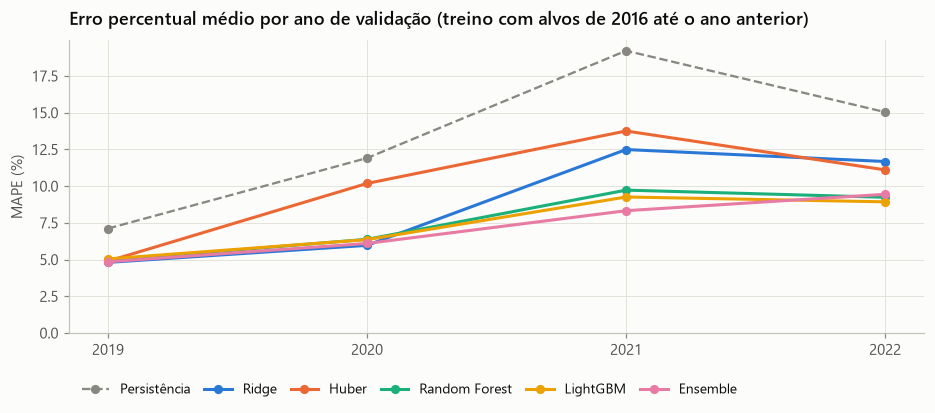

In [7]:
mostrar = ["Persistência (PIB_t = PIB_t-1)", "Ridge", "Huber", "Random Forest", "LightGBM", m.NOME_ENSEMBLE]
fig, ax = plt.subplots(figsize=(8.6, 3.9))
for nome in mostrar:
    serie = res_val[nome].por_ano["MAPE_%"]
    base = nome.startswith("Persist")
    ax.plot(serie.index, serie.values, color=viz.CORES_MODELOS[nome], lw=1.5 if base else 2,
            ls="--" if base else "-", marker="o", ms=5, label="Persistência" if base else nome.replace(" (Ridge + RF + LightGBM)", ""))
ax.set_xticks(m.ANOS_VALIDACAO)
ax.set_ylabel("MAPE (%)")
ax.set_ylim(0, None)
ax.legend(ncol=6, loc="upper left", bbox_to_anchor=(0, -0.13), columnspacing=1.0)
ax.set_title(f"Erro percentual médio por ano de validação (treino com alvos de {inicio_escolhido} até o ano anterior)")
fig.tight_layout()
viz.salva_figura(fig, "reg_validacao_mape_por_ano")
plt.show()

In [8]:
assert melhor_modelo == comparacao_val.drop(index=list(m.BASELINES)).index[0]  # mesma escolha da seção 3
print(f"Modelo escolhido: {melhor_modelo} | MAPE médio na validação: {comparacao_val.loc[melhor_modelo, 'MAPE_%']:.2f}%")

config = {
    "melhor_modelo": melhor_modelo,
    "inicio_janela": inicio_escolhido,
    "hiperparametros": params_modelos,
    "criterio": "MAPE médio na validação temporal 2019–2022",
    "variaveis_brasil_no_modelo": False,
}
_ = (DIR_RES / "config_regressao.json").write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")

Modelo escolhido: Ensemble (Ridge + RF + LightGBM) | MAPE médio na validação: 7.18%


### 4.1 Experimento: o PIB do Brasil ajuda?

O maior erro comum a todos os municípios é o **choque nominal do ano**: o boom de 2021, por exemplo, afetou todo mundo.
O PIB trimestral do Brasil (SIDRA 1846) sai antes do PIB municipal, e os 4 trimestres de 2024 já estão publicados, então testamos incluir as variações nominais do PIB e do VAB por setor do Brasil (`var_br_*`).

In [9]:
exp_brasil = {}
for nome in m.FABRICAS_REGRESSAO:
    for rotulo, incluir in [("sem PIB Brasil", False), ("com PIB Brasil", True)]:
        exp_brasil[(nome, rotulo)] = m.valida_temporal(nome, melhores[nome], dataset, inicio_escolhido,
                                                       incluir_brasil=incluir).media["MAPE_%"]
pd.Series(exp_brasil).unstack().assign(diferenca_pp=lambda t: t["com PIB Brasil"] - t["sem PIB Brasil"])

,com PIB Brasil,sem PIB Brasil,diferenca_pp
Huber,10.258,9.986,0.272
LightGBM,7.407,7.401,0.006
Random Forest,7.576,7.575,0.002
Ridge,7.880,8.738,-0.858


O ganho é **nulo ou negativo para os modelos de árvore** e irregular para os lineares. A variável é igual para todos os municípios num mesmo ano, então só há tantos valores distintos quanto anos de treino (7). É pouco para o modelo aprender a relação sem confundi-la com o "efeito do ano".
**Decisão:** as variáveis ficam no dataset (documentadas), mas **fora do modelo final**.

## 5. Teste final em 2023 (Etapa A)

Todos os modelos são treinados com alvos de **início a 2022**, com os hiperparâmetros escolhidos na validação, e preveem 2023. As previsões são comparadas com o **PIB oficial de 2023**.

In [10]:
treino = m.amostra_modelagem(dataset, inicio_escolhido, 2022)
teste = m.amostra_modelagem(dataset, m.ANO_TESTE, m.ANO_TESTE)
print(f"Treino: {len(treino):,} linhas (alvos {treino['ano'].min()}–{treino['ano'].max()}) | Teste: {len(teste):,} municípios")

prev_teste, modelos_teste = {}, {}
for nome in m.BASELINES:
    prev_teste[nome] = m.BASELINES[nome](teste)
for nome, params in params_modelos.items():
    prev_teste[nome], modelos_teste[nome] = m.treina_preve_modelo(nome, params, treino, teste, numericas, categoricas)

resultado_teste = pd.DataFrame({n: m.avalia_previsao(teste, g) for n, g in prev_teste.items()}).T.sort_values("MAPE_%")
resultado_teste.to_csv(DIR_RES / "regressao_teste_2023.csv")
resultado_teste

Treino: 8,337 linhas (alvos 2016–2022) | Teste: 1,191 municípios


,R2_pib,MAPE_%,MdAPE_%,R2_log_pib,R2_crescimento
Huber,0.994,6.592,4.925,0.995,0.434
Ensemble (Ridge + RF + LightGBM),0.995,6.958,5.564,0.994,0.353
Random Forest,0.996,7.051,5.777,0.994,0.341
LightGBM,0.995,7.238,5.792,0.994,0.308
Ridge,0.993,7.289,5.882,0.994,0.317
Crescimento da UF em t-1,0.993,9.650,8.060,0.990,-0.137
Média 3 anos do município,0.990,10.618,7.621,0.987,-0.460
Persistência (PIB_t = PIB_t-1),0.989,12.923,11.817,0.983,-0.899


In [11]:
# Previsões de 2023 de todos os modelos (para análise e para a Fase 5)
saida = teste[["cod_ibge", "municipio", "uf", "ano", "pib_l1", "pib", "cresc_pib_pct", "categoria_crescimento"]].copy()
for nome, g in prev_teste.items():
    chave = {"Persistência (PIB_t = PIB_t-1)": "persistencia", "Média 3 anos do município": "media_3a",
             "Crescimento da UF em t-1": "uf_t1", m.NOME_ENSEMBLE: "ensemble"}.get(nome, nome.lower().replace(" ", "_"))
    saida[f"pib_prev_{chave}"] = teste["pib_l1"].to_numpy() * np.exp(g)
DIR_PRED.mkdir(parents=True, exist_ok=True)
saida.to_csv(DIR_PRED / "regressao_teste_2023_todos_modelos.csv", index=False)
print("Gravado:", (DIR_PRED / "regressao_teste_2023_todos_modelos.csv").name)

Gravado: regressao_teste_2023_todos_modelos.csv


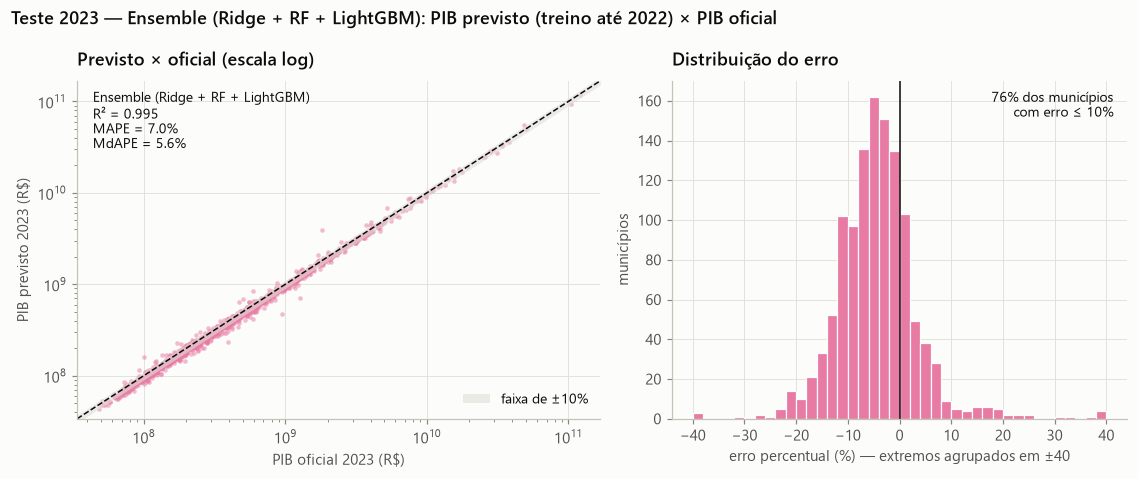

In [12]:
g_best = prev_teste[melhor_modelo]
pib_prev = teste["pib_l1"].to_numpy() * np.exp(g_best)
real = teste["pib"].to_numpy()
erro_pct = (pib_prev / real - 1) * 100

fig, eixos = plt.subplots(1, 2, figsize=(10.4, 4.4), gridspec_kw={"width_ratios": [1.15, 1]})
ax = eixos[0]
ax.scatter(real * 1000, pib_prev * 1000, s=9, alpha=0.5, color=viz.CORES_MODELOS[melhor_modelo], linewidths=0)
lims = [real.min() * 1000 * 0.7, real.max() * 1000 * 1.4]
ax.plot(lims, lims, color=viz.TINTA, lw=1, ls="--")
ax.fill_between(lims, [l * 0.9 for l in lims], [l * 1.1 for l in lims], color=viz.GRADE, alpha=0.6, lw=0,
                label="faixa de ±10%")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("PIB oficial 2023 (R$)"); ax.set_ylabel("PIB previsto 2023 (R$)")
met = resultado_teste.loc[melhor_modelo]
ax.text(0.03, 0.97, f"{melhor_modelo}\nR² = {met['R2_pib']:.3f}\nMAPE = {met['MAPE_%']:.1f}%\nMdAPE = {met['MdAPE_%']:.1f}%",
        transform=ax.transAxes, va="top", fontsize=9, color=viz.TINTA)
ax.legend(loc="lower right")
ax.set_title("Previsto × oficial (escala log)")

ax = eixos[1]
ax.hist(np.clip(erro_pct, -40, 40), bins=np.arange(-40, 41, 2), color=viz.CORES_MODELOS[melhor_modelo],
        edgecolor=viz.SUPERFICIE, linewidth=0.8)
ax.axvline(0, color=viz.TINTA, lw=1)
dentro10 = (np.abs(erro_pct) <= 10).mean() * 100
ax.text(0.97, 0.97, f"{dentro10:.0f}% dos municípios\ncom erro ≤ 10%", transform=ax.transAxes,
        ha="right", va="top", fontsize=9, color=viz.TINTA)
ax.set_xlabel("erro percentual (%) — extremos agrupados em ±40")
ax.set_ylabel("municípios")
ax.set_title("Distribuição do erro")
fig.suptitle(f"Teste 2023 — {melhor_modelo}: PIB previsto (treino até 2022) × PIB oficial",
             x=0.01, ha="left", fontsize=11.5, fontweight="semibold")
fig.tight_layout()
viz.salva_figura(fig, "fig_regressao_previsto_real_2023")
plt.show()

## 6. Análise dos erros (melhor modelo, 2023)

In [13]:
analise = teste[["cod_ibge", "municipio", "uf", "porte", "pib_l1", "pib", "cresc_pib_pct"]].copy()
analise["pib_prev"] = pib_prev
analise["cresc_prev_pct"] = (np.exp(g_best) - 1) * 100
analise["erro_pct"] = erro_pct
analise["erro_abs_pct"] = np.abs(erro_pct)

por_uf = analise.groupby("uf").agg(municipios=("erro_pct", "size"), MAPE=("erro_abs_pct", "mean"),
                                   MdAPE=("erro_abs_pct", "median"), vies_mediano=("erro_pct", "median"))
por_porte = analise.groupby("porte", observed=True).agg(municipios=("erro_pct", "size"), MAPE=("erro_abs_pct", "mean"),
                                                        MdAPE=("erro_abs_pct", "median"), vies_mediano=("erro_pct", "median"))
display(por_uf)
display(por_porte)

,municipios,MAPE,MdAPE,vies_mediano
uf,,,,
PR,399,5.779,4.636,-4.030
RS,497,7.374,5.751,-3.917
SC,295,7.851,6.880,-6.298


,municipios,MAPE,MdAPE,vies_mediano
porte,,,,
ate_5mil,436,7.617,6.471,-5.200
5_10mil,265,7.059,5.431,-4.812
10_20mil,216,6.966,5.419,-4.594
20_50mil,163,6.047,5.078,-4.535
50_100mil,55,6.220,4.956,-2.954
100_500mil,51,4.690,3.924,-3.117
acima_500mil,5,4.746,1.628,-1.628


In [14]:
# Os 10 maiores erros percentuais
analise.nlargest(10, "erro_abs_pct")[["municipio", "uf", "pib_l1", "pib", "pib_prev", "cresc_pib_pct", "cresc_prev_pct", "erro_pct"]]

,municipio,uf,pib_l1,pib,pib_prev,cresc_pib_pct,cresc_prev_pct,erro_pct
15077,Horizontina,RS,"3,718,636.000","1,828,050.000","3,905,994.461",-50.841,5.038,113.670
17270,Poço das Antas,RS,"154,362.000","100,774.000","160,725.022",-34.716,4.122,59.491
10147,Piratuba,SC,"419,814.000","953,671.000","478,050.345",127.165,13.872,-49.873
18511,São José do Norte,RS,"651,593.000","1,273,464.000","715,974.486",95.439,9.881,-43.777
17865,Salto do Jacuí,RS,"844,872.000","594,921.000","847,243.378",-29.584,0.281,42.413
4724,Porto Amazonas,PR,"243,728.000","391,662.000","232,782.214",60.696,-4.491,-40.566
17151,Pinhal Grande,RS,"727,915.000","500,998.000","692,327.587",-31.174,-4.889,38.190
18902,São Vicente do Sul,RS,"646,468.000","469,886.000","646,457.795",-27.315,-0.002,37.578
17032,Pedras Altas,RS,"358,700.000","172,852.000","228,884.901",-51.812,-36.190,32.417
16199,Montenegro,RS,"6,467,582.000","5,259,437.000","6,880,383.777",-18.680,6.383,30.820


## 7. Importância das variáveis

Usamos a **importância por permutação** no teste de 2023: quanto o MAPE piora quando os valores de uma variável são embaralhados.
Ela é comparável entre tipos de modelo e mede o efeito no erro que interessa.

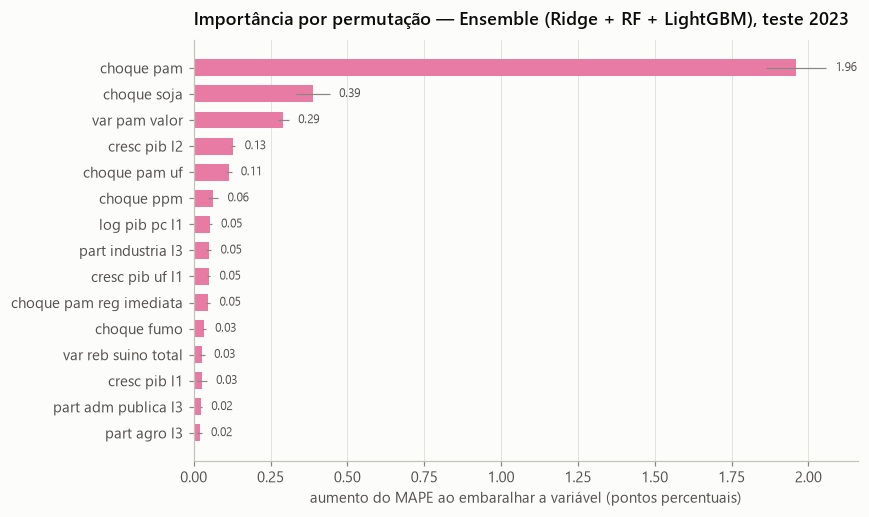

In [15]:
from sklearn.inspection import permutation_importance

modelo_best = modelos_teste[melhor_modelo]
X_teste = teste[numericas + categoricas]

def neg_mape_crescimento(estimador, X, y):
    g = estimador.predict(X)
    return -np.mean(np.abs(np.exp(g - y) - 1)) * 100   # = -MAPE do PIB

perm = permutation_importance(modelo_best, X_teste, teste["cresc_pib_log"], scoring=neg_mape_crescimento,
                              n_repeats=10, random_state=m.SEMENTE, n_jobs=1)
importancia = pd.DataFrame({"aumento_MAPE_pp": perm.importances_mean, "desvio": perm.importances_std},
                           index=X_teste.columns).sort_values("aumento_MAPE_pp", ascending=False)
importancia.to_csv(DIR_RES / "regressao_importancia_permutacao_2023.csv")

top = importancia.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh([c.replace("_", " ") for c in top.index], top["aumento_MAPE_pp"], color=viz.CORES_MODELOS[melhor_modelo],
        height=0.65, xerr=top["desvio"], error_kw=dict(ecolor=viz.TINTA_SUAVE, lw=0.8))
for i, (v, dp) in enumerate(zip(top["aumento_MAPE_pp"], top["desvio"])):
    ax.text(v + dp + 0.03, i, f"{v:.2f}", va="center", fontsize=8, color=viz.TINTA_SECUNDARIA)
ax.set_xlabel("aumento do MAPE ao embaralhar a variável (pontos percentuais)")
ax.grid(axis="y", visible=False)
ax.set_title(f"Importância por permutação — {melhor_modelo}, teste 2023")
fig.tight_layout()
viz.salva_figura(fig, "reg_importancia_permutacao")
plt.show()

## 8. Conclusões parciais

**Escolha do modelo, só pela validação 2019–2022**
- Todos os modelos treinados superam com folga os baselines. A persistência, que só copia o PIB do ano anterior, erra em média 13,3% na validação.
- O melhor par foi o **ensemble (média de Ridge, Random Forest e LightGBM) treinado com alvos a partir de 2016**: **MAPE médio de 7,18%**, MdAPE de 5,04% e pior ano com 9,45%. Em seguida vêm LightGBM (7,40%), Random Forest (7,58%), Ridge (8,74%) e Huber (9,99%).
- **Janela de treino:** a de 2016 foi melhor que as de 2010 e 2013 para o ensemble e para os modelos de árvore. Os anos mais antigos, com outro regime de inflação e crescimento, atrapalham mais do que ajudam.
- **O ensemble venceu pela estabilidade:** foi o melhor em 2021, o ano do boom de commodities (8,3%, contra 9,3% do LightGBM e 12,5% do Ridge). Os modelos lineares erram muito nos anos de choque.
- **PIB nacional (experimento):** as variáveis de PIB do Brasil não ajudaram os modelos de árvore (diferença de +0,01 pp) e ficaram de fora.

**Teste em 2023 (Etapa A), contra o PIB oficial**
- **Resultado:** o ensemble obteve **R² = 0,995**, **MAPE = 6,96%** e MdAPE = 5,56%. **76% dos municípios ficaram com erro de até 10%**.
- **Ganho sobre o baseline:** a persistência erra 12,92% em 2023, então o erro médio caiu **46%**.
- **R² do crescimento = 0,35:** o modelo explica cerca de um terço da variação de crescimento entre municípios, que é a parte difícil. O R² do nível do PIB é alto até para a persistência (0,989), por isso não serve sozinho como medida de qualidade.
- **Ordem dos modelos no teste:** o Huber, pior na validação, foi o melhor em 2023 (6,59%). A ordem muda de ano para ano e as diferenças no teste são pequenas (6,6% a 7,3%). Mudar a escolha depois de ver o teste seria vazamento de informação, então mantivemos o modelo escolhido pela validação.

**Onde o modelo erra**
- **Viés comum:** o modelo **subestima 2023** (erro mediano de -4%, em todos os estados; em SC, -6,3%). O PIB nominal do Sul cresceu 9,6% em 2023, e o modelo previu 6,6% para o agregado da região. O ano foi mais forte do que os indicadores disponíveis antecipavam. É o mesmo componente comum do ano visto na validação, e é a principal limitação.
- **Tamanho do município:** municípios pequenos têm erro maior (7,6% abaixo de 5 mil habitantes, contra 4,7% entre 100 e 500 mil). Neles, um único empreendimento muda o PIB.
- **Maiores erros:** são choques **industriais ou energéticos pontuais**, como Horizontina (-51%), Piratuba (+127%) e São José do Norte (+95%), que não aparecem em nenhuma das fontes municipais usadas (agro, pecuária, população).

**O que o modelo usa**
- O **choque agrícola do ano** domina: embaralhar `choque_pam` aumenta o MAPE em 1,96 pp. Depois vêm a soja (0,39 pp), a variação do valor da PAM (0,29 pp), o crescimento de dois anos antes (0,13 pp) e o choque agrícola da UF (0,11 pp).
- Isso confirma a decisão da Fase 3 de usar os dados agropecuários do próprio ano, já publicados para 2024.

**Para o relatório:** figura `fig_regressao_previsto_real_2023` e as tabelas `regressao_validacao_comparacao.csv` e `regressao_teste_2023.csv` (em `reports/resultados/`).